In [173]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

In [174]:
df = pd.read_csv('data/RRCA_baseflow.csv')

### Reformatting the dates from days since 01/01/0000 to M-D-Y
--------------------------------------------------------------

In [175]:
baseflow_df = df.copy()
# offset is the number of days between 01/01/0000 and 01/01/1900 (693963)
offset = 693963
baseflow_df['days_since_1900'] = baseflow_df.Date - offset
baseflow_df['offset_date'] = pd.to_datetime(baseflow_df.days_since_1900.astype('int'), unit='D', origin=pd.Timestamp('1900-01-01'))
print(baseflow_df['offset_date'])

0       1945-11-30
1       1945-12-31
2       1946-01-28
3       1946-02-28
4       1946-03-30
           ...    
15586   1976-03-30
15587   1976-04-30
15588   1976-05-30
15589   1976-06-30
15590   1976-07-31
Name: offset_date, Length: 15591, dtype: datetime64[s]


### Preliminary Column Analysis (so we know what we're working with)
--------------------------------------------------------------------

**Where is our data from?**

Notes:
- The dataset is labeled *RRCA_baseflow.csv*
    - In the context of bodies of water, *RRCA* might refer to *Republican River Compact Administration*.
        - The *Republican River* is a river that runs east from Colorado through Nebraska and Kansas.
- It looks like the RRCA made a groundwater flow model to represent characteristics of the Republican River Basin.

Website: (https://www.republicanrivercompact.org/)

In [176]:
print(f"Minimum x coordinate(...?): {min(baseflow_df['x'])}")
print(f"Maximum x coordinate: {max(baseflow_df['x'])}")
print(f"Minimum y coordinate: {min(baseflow_df['y'])}")
print(f"Maximum y coordinate: {max(baseflow_df['y'])}")

Minimum x coordinate(...?): 721870
Maximum x coordinate: 1941550
Minimum y coordinate: 14387040
Maximum y coordinate: 14767200


I'm not sure what to make off these positions/coordinates. They don't seem to be WGS84 coordinates.

In [177]:
print(min(baseflow_df['offset_date']))
print(max(baseflow_df['offset_date']))

1939-09-30 00:00:00
2000-08-30 00:00:00


The dataset spans 1939-2000. This doesn't line up with the initial scope of the model (1918-2000).

Here's the documentation on the model: (https://www.republicanrivercompact.org/v12p/RRCAModelDocumentation.pdf)
After digging in the documentation, I found that the model works on the premise that there was no recharge from ground water irrigation prior to 1940 (pg. 14). (I'm sorry if that understanding misrepresents the paper)

In [178]:
pre40s = baseflow_df[baseflow_df.offset_date< '1940-01-01']
print(pre40s[pre40s.Irrigation_pumping != 0])

Empty DataFrame
Columns: [Date, Segment_id, x, y, Evapotranspiration, Precipitation, Irrigation_pumping, Observed, days_since_1900, offset_date]
Index: []


So, the dataset is from the inaugural/2003 use of the model (also referred to as Version 12p). We can use this to explain the dataset and interpret certain variables (notably what the coordinates mean).

In [179]:
display(baseflow_df)

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,days_since_1900,offset_date
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,16769,1945-11-30
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,16800,1945-12-31
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,16828,1946-01-28
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,16859,1946-02-28
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,16889,1946-03-30
...,...,...,...,...,...,...,...,...,...,...
15586,721810,98,721870,14387040,0.00,0.00,0.0,0.298500,27847,1976-03-30
15587,721841,98,721870,14387040,0.00,0.00,0.0,0.211475,27878,1976-04-30
15588,721871,98,721870,14387040,0.00,0.00,0.0,0.122951,27908,1976-05-30
15589,721902,98,721870,14387040,0.00,0.00,0.0,0.120000,27939,1976-06-30


### WHAT HAPPEND in 1950?

--- Correlation Matrix ---
                    Evapotranspiration  Precipitation  Irrigation_pumping  \
Evapotranspiration            1.000000       0.428491           -0.495154   
Precipitation                 0.428491       1.000000           -0.154587   
Irrigation_pumping           -0.495154      -0.154587            1.000000   
Observed                      0.062248       0.270033            0.054757   

                    Observed  
Evapotranspiration  0.062248  
Precipitation       0.270033  
Irrigation_pumping  0.054757  
Observed            1.000000  

--- Yearly Summary (Head) ---
   Year  Evapotranspiration  Precipitation  Irrigation_pumping   Observed
0  1940            1.115714      12.902143            0.000000  34.152220
1  1941            3.054798      13.135954           -0.018842  63.461244
2  1942            3.001019      23.492778           -0.012034  90.321743
3  1943            3.123333      23.125000           -0.013724  93.813370
4  1944            3.829623    

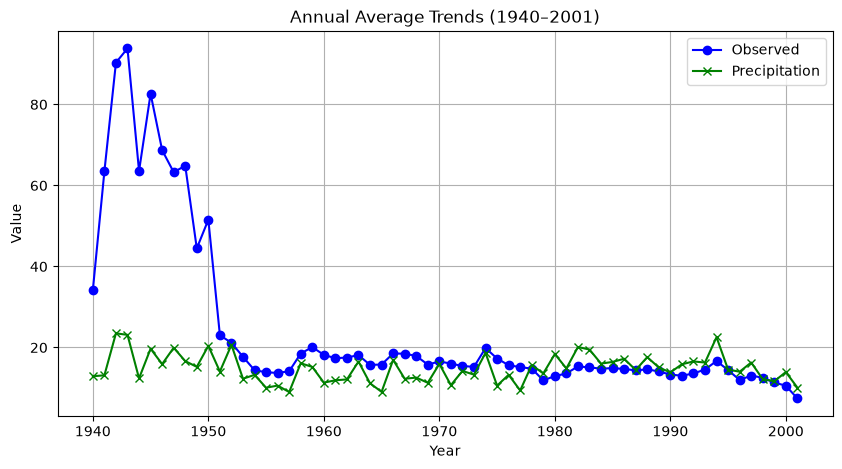

In [180]:
df['datetime'] = pd.to_datetime(df['Date'].apply(dt.date.fromordinal))
df['Year'] = df['datetime'].dt.year
# 3. Correlation Analysis
corr_cols = ['Evapotranspiration', 'Precipitation', 'Irrigation_pumping', 'Observed']
corr_matrix = df[corr_cols].corr()
print('--- Correlation Matrix ---')
print(corr_matrix)

# 4. Temporal Aggregation (Yearly Mean)
yearly_df = df.groupby('Year')[corr_cols].mean().reset_index()
print('\n--- Yearly Summary (Head) ---')
print(yearly_df.head())

# 5. Spatial Aggregation (Segment-Specific Summary)
segment_summary = (
    df.groupby('Segment_id')[corr_cols]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
print('\n--- Segment Summary (Head) ---')
print(segment_summary.head())

# 6. Optional: Quick Plotting
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_df['Year'], yearly_df['Observed'], marker='o', color='b', label='Observed'
)
plt.plot(
    yearly_df['Year'],
    yearly_df['Precipitation'],
    marker='x',
    color='g',
    label='Precipitation',
)
plt.title('Annual Average Trends (1940–2001)')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

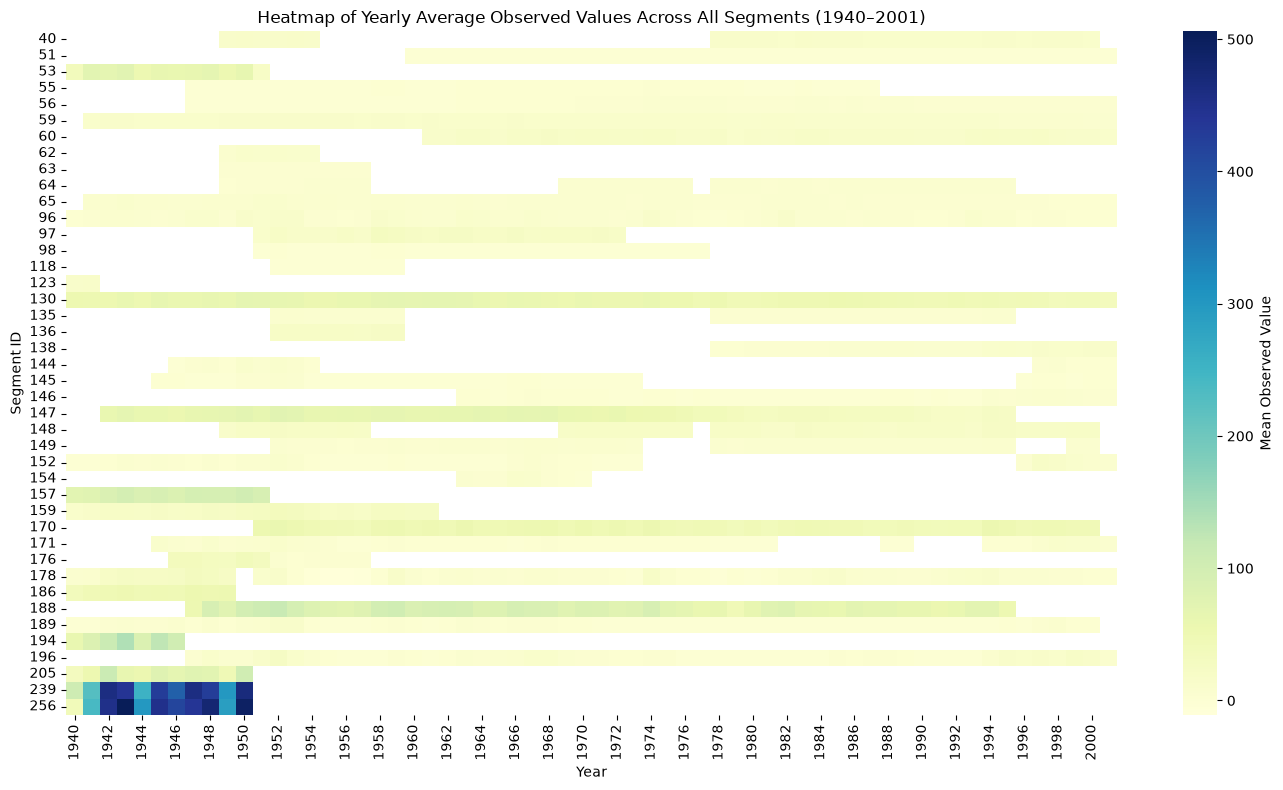

In [181]:
# 2. Create a pivot table: Rows = Segment_id, Columns = Year, Values = Mean Observed
pivot_obs = df.pivot_table(
    index='Segment_id', columns='Year', values='Observed', aggfunc='mean'
)

# 3. Plot a Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_obs, cmap='YlGnBu', cbar_kws={'label': 'Mean Observed Value'})
plt.title(
    'Heatmap of Yearly Average Observed Values Across All Segments (1940–2001)'
)
plt.xlabel('Year')
plt.ylabel('Segment ID')
plt.tight_layout()
plt.show()

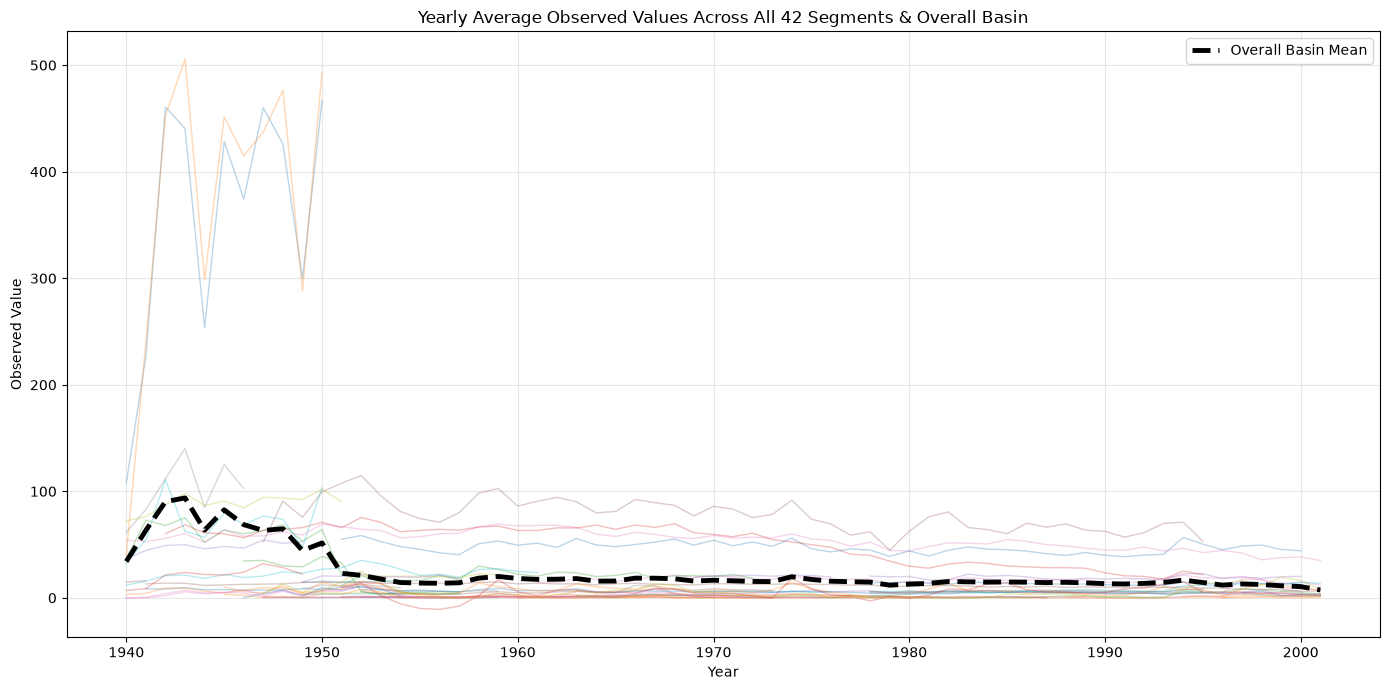

In [182]:




# 2. Group by Year and Segment for ALL segments (no filtering)
segment_yearly = df.groupby(['Year', 'Segment_id'])['Observed'].mean().unstack()

# 3. Calculate the overall mean across all segments for each year
segment_yearly['Overall Mean'] = df.groupby('Year')['Observed'].mean()

# 4. Plotting
plt.figure(figsize=(14, 7))

for col in segment_yearly.columns:
  if col == 'Overall Mean':
    # Style the overall mean distinctly so it stands out prominently
    plt.plot(
        segment_yearly.index,
        segment_yearly[col],
        label='Overall Basin Mean',
        color='black',
        linewidth=3.5,
        linestyle='--',
        zorder=10,
    )
  else:
    # Plot individual segment lines with low opacity (alpha) to avoid a cluttered legend/view
    plt.plot(
        segment_yearly.index,
        segment_yearly[col],
        alpha=0.3,
        linewidth=1,
        label='_nolegend_',
    )

plt.title(
    'Yearly Average Observed Values Across All 42 Segments & Overall Basin'
)
plt.xlabel('Year')
plt.ylabel('Observed Value')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

notes 1940 is so low becues it does not have the full year of data

at first the data set was not tracking very many check points and the few that they where checking 

main-stem dams and reservoirs across the Republican River Basin (such as Harlan County Lake and Swanson Lake) between 1949 and 1953, those exact valley floors were permanently flooded and converted into regulated reservoir pools. Natural free-flowing segment accounting at those specific geographic coordinates was retired or entirely restructured.

something I found out doing my resarch is 

Low-Numbered Segments (e.g., 51, 55, 56): These typically represent small, localized headwater streams, minor creeks, or upper sub-basins. Because they drain very small areas, their natural baseflow and observed water volumes are tiny (often close to 0 or under 2 units).

High-Numbered Segments (e.g., 239, 256): These represent the main stem of major river channels or primary downstream confluences (such as the main trunk of the Republican River approaching major state-line gaging stations).

what I think we should do we will need to make a pre- and post-1950 model



In [ ]:



# 2. Sort critically by segment and time before creating lags
df = df.sort_values(by=['Segment_id', 'datetime']).reset_index(drop=True)


# 3. Function to build lagged features grouped by each Segment
def add_all_lags(subset_df):
  subset_df = subset_df.copy()

  # Precipitation lags (1 and 2 months back)
  subset_df['Precip_lag1'] = subset_df.groupby('Segment_id')[
      'Precipitation'
  ].shift(1)
  subset_df['Precip_lag2'] = subset_df.groupby('Segment_id')[
      'Precipitation'
  ].shift(2)

  # Evapotranspiration lag (1 month back)
  subset_df['Evap_lag1'] = subset_df.groupby('Segment_id')[
      'Evapotranspiration'
  ].shift(1)

  # Autoregressive lag (Flow from last month)
  subset_df['Observed_lag1'] = subset_df.groupby('Segment_id')['Observed'].shift(
      1
  )

  # Drop rows with NaNs created by shifting the first two months of each segment
  subset_df = subset_df.dropna()
  return subset_df


# Apply lagging to the entire dataset first
df_lagged = add_all_lags(df)

# 4. Split into Pre-1950 and Post-1950 Eras
df_pre = df_lagged[df_lagged['Year'] < 1950].copy()
df_post = df_lagged[df_lagged['Year'] >= 1950].copy()


# 5. Function to format feature table (X) and target vector (y)
def prepare_tables(subset_df):
  # Select all numerical features (current + lags) plus Segment_id
  feature_cols = [
      'Precipitation',
      'Evapotranspiration',
      'Irrigation_pumping',
      'Precip_lag1',
      'Precip_lag2',
      'Evap_lag1',
      'Observed_lag1',
      'Segment_id',
  ]

  data = subset_df[feature_cols].copy()

  # One-hot encode Segment_id (drop_first=True prevents the dummy variable trap)
  X = pd.get_dummies(data, columns=['Segment_id'], drop_first=True)
  y = subset_df['Observed']

  return X, y


# Build final training tables for both eras
X_pre, y_pre = prepare_tables(df_pre)
X_post, y_post = prepare_tables(df_post)

# 6. Train and Evaluate Pre-1950 Model
model_pre = LinearRegression()
model_pre.fit(X_pre, y_pre)
preds_pre = model_pre.predict(X_pre)
print(f'=== Pre-1950 Era Model ===')
print(f'Training Samples: {len(y_pre)}')
print(f'R2 Score: {r2_score(y_pre, preds_pre):.4f}')

# 7. Train and Evaluate Post-1950 Model (Regulated Era)
model_post = LinearRegression()
model_post.fit(X_post, y_post)
preds_post = model_post.predict(X_post)
print(f'\n=== Post-1950 Era Model (Dams & Regulation) ===')
print(f'Training Samples: {len(y_post)}')
print(f'R2 Score: {r2_score(y_post, preds_post):.4f}')
print("pre 1950 table")
display(model_pre)
print("post 1950 table")
display(model_post)

=== Pre-1950 Era Model ===
Training Samples: 2207
R2 Score: 0.9193

=== Post-1950 Era Model (Dams & Regulation) ===
Training Samples: 13300
R2 Score: 0.9286


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](36,)","[ -0.01, -1.34,-31.42,..., 24.48, 96.97,102.23]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](36,)","['Precipitation','Evapotranspiration','Irrigation_pumping',..., 'Segment_id_205','Segment_id_239','Segment_id_256']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.37
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,36
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(36)


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,datetime,Year,Precip_lag1,Precip_lag2,Evap_lag1,Observed_lag1
3,711859,40,1798990,14561280,0.00,29.07,0.0,15.877097,1950-01-02,1950,20.68,20.68,0.22,16.007097
4,711887,40,1798990,14561280,0.16,29.07,0.0,15.828305,1950-01-30,1950,29.07,20.68,0.00,15.877097
5,711918,40,1798990,14561280,0.15,29.07,0.0,15.868305,1950-03-02,1950,29.07,29.07,0.16,15.828305
6,711948,40,1798990,14561280,1.73,29.07,0.0,15.849590,1950-04-01,1950,29.07,29.07,0.15,15.868305
7,711979,40,1798990,14561280,2.32,29.07,0.0,15.764590,1950-05-02,1950,29.07,29.07,1.73,15.849590
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15586,711948,256,1941550,14524320,1.73,30.85,0.0,655.172131,1950-04-01,1950,30.85,30.85,0.15,539.610169
15587,711979,256,1941550,14524320,2.32,30.85,0.0,739.672130,1950-05-02,1950,30.85,30.85,1.73,655.172131
15588,712009,256,1941550,14524320,4.41,30.85,0.0,697.475410,1950-06-01,1950,30.85,30.85,2.32,739.672130
15589,712040,256,1941550,14524320,8.19,30.85,0.0,515.475410,1950-07-02,1950,30.85,30.85,4.41,697.475410
